Question 1: IQR-Based Outlier Detection in Sales Data

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Transaction_ID": range(1, 13),
    "Sales": [120, 150, 180, 200, 220, 240,
              260, 280, 300, 350, 400, 2500],
    "Quantity": [1, 2, 2, 3, 3, 4,
                 4, 5, 5, 6, 7, 40]
})

# IQR for Sales
Q1_sales = df["Sales"].quantile(0.25)
Q3_sales = df["Sales"].quantile(0.75)
IQR_sales = Q3_sales - Q1_sales

lower_sales = Q1_sales - 1.5 * IQR_sales
upper_sales = Q3_sales + 1.5 * IQR_sales

# IQR for Quantity
Q1_qty = df["Quantity"].quantile(0.25)
Q3_qty = df["Quantity"].quantile(0.75)
IQR_qty = Q3_qty - Q1_qty

lower_qty = Q1_qty - 1.5 * IQR_qty
upper_qty = Q3_qty + 1.5 * IQR_qty

# Outlier flags
df["Sales_Outlier"] = (
    (df["Sales"] < lower_sales) |
    (df["Sales"] > upper_sales)
)

df["Quantity_Outlier"] = (
    (df["Quantity"] < lower_qty) |
    (df["Quantity"] > upper_qty)
)

print("Sales Q1:", Q1_sales)
print("Sales Q3:", Q3_sales)
print("Sales IQR:", IQR_sales)
print("Sales Lower Bound:", lower_sales)
print("Sales Upper Bound:", upper_sales)

print("\nQuantity Q1:", Q1_qty)
print("Quantity Q3:", Q3_qty)
print("Quantity IQR:", IQR_qty)
print("Quantity Lower Bound:", lower_qty)
print("Quantity Upper Bound:", upper_qty)

print("\nOutlier Detection Result:")
print(df)


Sales Q1: 195.0
Sales Q3: 312.5
Sales IQR: 117.5
Sales Lower Bound: 18.75
Sales Upper Bound: 488.75

Quantity Q1: 2.75
Quantity Q3: 5.25
Quantity IQR: 2.5
Quantity Lower Bound: -1.0
Quantity Upper Bound: 9.0

Outlier Detection Result:
    Transaction_ID  Sales  Quantity  Sales_Outlier  Quantity_Outlier
0                1    120         1          False             False
1                2    150         2          False             False
2                3    180         2          False             False
3                4    200         3          False             False
4                5    220         3          False             False
5                6    240         4          False             False
6                7    260         4          False             False
7                8    280         5          False             False
8                9    300         5          False             False
9               10    350         6          False             False
10    

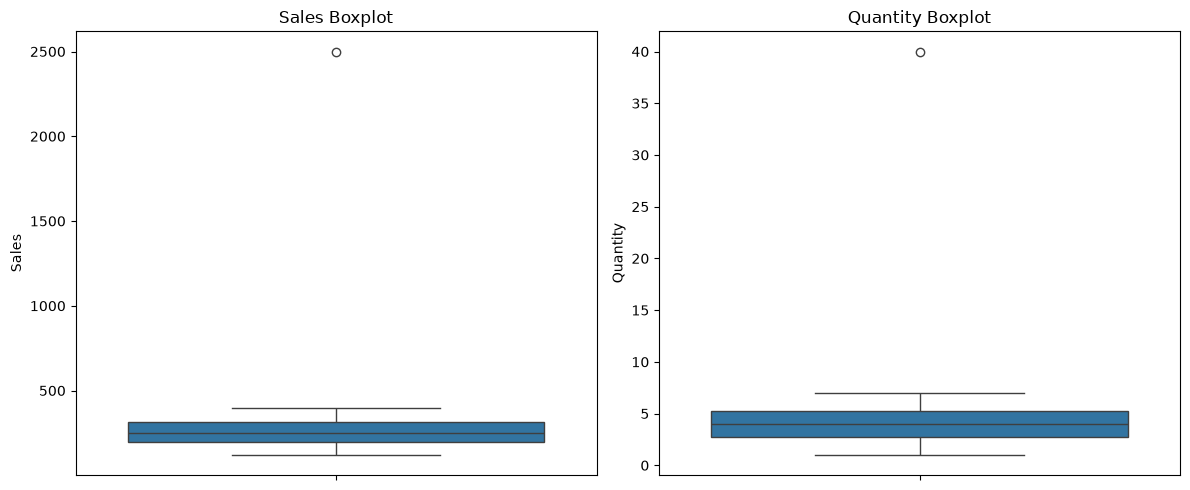

Original Statistics:
             Sales   Quantity
mean    433.333333   6.833333
median  250.000000   4.000000
std     655.776200  10.590161

Filtered Statistics:
             Sales  Quantity
mean    245.454545  3.818182
median  240.000000  4.000000
std      84.304642  1.834022


In [2]:

# Boxplots
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df["Sales"])
plt.title("Sales Boxplot")

plt.subplot(1, 2, 2)
sns.boxplot(y=df["Quantity"])
plt.title("Quantity Boxplot")

plt.tight_layout()
plt.show()

# Remove records flagged in either feature
filtered_df = df[
    ~(df["Sales_Outlier"] | df["Quantity_Outlier"])
]

# Compare statistics
original_stats = df[["Sales", "Quantity"]].agg(
    ["mean", "median", "std"]
)

filtered_stats = filtered_df[["Sales", "Quantity"]].agg(
    ["mean", "median", "std"]
)

print("Original Statistics:")
print(original_stats)

print("\nFiltered Statistics:")
print(filtered_stats)


Question 2: Z-Score Detection and Statistical Interpretation

    Machine_ID  Temperature  Pressure  Temperature_Z  Pressure_Z  \
0            1           68        30         -0.519      -0.614   
1            2           70        32         -0.357      -0.355   
2            3           69        31         -0.438      -0.485   
3            4           72        33         -0.195      -0.226   
4            5           71        32         -0.276      -0.355   
5            6           73        34         -0.115      -0.097   
6            7           70        31         -0.357      -0.485   
7            8           74        33         -0.034      -0.226   
8            9           68        32         -0.519      -0.355   
9           10           72        35         -0.195       0.032   
10          11           71        34         -0.276      -0.097   
11          12          115        60          3.282       3.264   

    Temperature_Outlier  Pressure_Outlier  
0                 False             False  
1                 False    

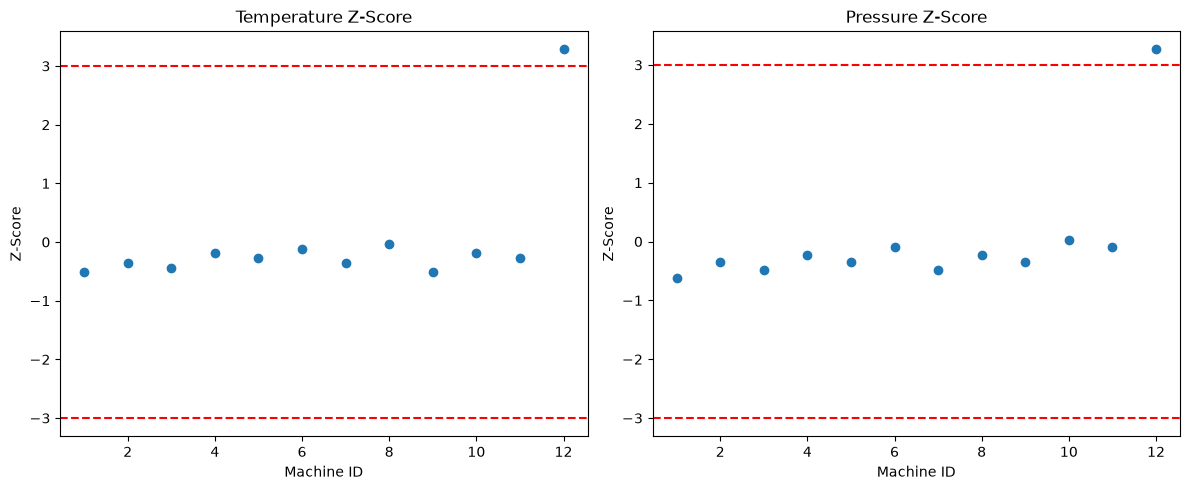

In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import zscore

df = pd.DataFrame({
    "Machine_ID": range(1, 13),
    "Temperature": [68, 70, 69, 72, 71, 73,
                    70, 74, 68, 72, 71, 115],
    "Pressure": [30, 32, 31, 33, 32, 34,
                 31, 33, 32, 35, 34, 60]
})

# Calculate Z-scores
df["Temperature_Z"] = zscore(df["Temperature"])
df["Pressure_Z"] = zscore(df["Pressure"])

# Identify outliers using threshold 3
df["Temperature_Outlier"] = abs(
    df["Temperature_Z"]
) > 3

df["Pressure_Outlier"] = abs(
    df["Pressure_Z"]
) > 3

print(df.round(3))

# Scatterplots
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(df["Machine_ID"], df["Temperature_Z"])
plt.axhline(3, linestyle="--", color="red")
plt.axhline(-3, linestyle="--", color="red")
plt.title("Temperature Z-Score")
plt.xlabel("Machine ID")
plt.ylabel("Z-Score")

plt.subplot(1, 2, 2)
plt.scatter(df["Machine_ID"], df["Pressure_Z"])
plt.axhline(3, linestyle="--", color="red")
plt.axhline(-3, linestyle="--", color="red")
plt.title("Pressure Z-Score")
plt.xlabel("Machine ID")
plt.ylabel("Z-Score")

plt.tight_layout()
plt.show()


In [4]:

# Compare threshold 2 and 3

for column in ["Temperature_Z", "Pressure_Z"]:

    count_2 = (abs(df[column]) > 2).sum()
    count_3 = (abs(df[column]) > 3).sum()

    print("\nFeature:", column)
    print("Outliers at threshold 2:", count_2)
    print("Outliers at threshold 3:", count_3)



Feature: Temperature_Z
Outliers at threshold 2: 1
Outliers at threshold 3: 1

Feature: Pressure_Z
Outliers at threshold 2: 1
Outliers at threshold 3: 1


Question 3: Comparing IQR and Z-Score on Skewed Data

In [5]:

import pandas as pd
import numpy as np
from scipy.stats import zscore

df = pd.DataFrame({
    "Transaction_Amount": [
        100, 120, 130, 150, 160, 170,
        180, 200, 220, 250, 300, 350,
        400, 450, 500, 800, 1200, 10000
    ]
})

# IQR calculation
Q1 = df["Transaction_Amount"].quantile(0.25)
Q3 = df["Transaction_Amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Z-score calculation
df["Z_Score"] = zscore(df["Transaction_Amount"])

# Outlier flags
df["IQR_Outlier"] = (
    (df["Transaction_Amount"] < lower_bound) |
    (df["Transaction_Amount"] > upper_bound)
)

df["Z_Score_Outlier"] = abs(df["Z_Score"]) > 3

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nComparison Table:")
print(df.round(3))

# Records detected by only one method
print("\nOnly IQR:")
print(df[
    df["IQR_Outlier"] & ~df["Z_Score_Outlier"]
])

print("\nOnly Z-Score:")
print(df[
    df["Z_Score_Outlier"] & ~df["IQR_Outlier"]
])


Q1: 162.5
Q3: 437.5
IQR: 275.0
Lower Bound: -250.0
Upper Bound: 850.0

Comparison Table:
    Transaction_Amount  Z_Score  IQR_Outlier  Z_Score_Outlier
0                  100   -0.346        False            False
1                  120   -0.337        False            False
2                  130   -0.332        False            False
3                  150   -0.323        False            False
4                  160   -0.319        False            False
5                  170   -0.314        False            False
6                  180   -0.310        False            False
7                  200   -0.301        False            False
8                  220   -0.292        False            False
9                  250   -0.278        False            False
10                 300   -0.256        False            False
11                 350   -0.234        False            False
12                 400   -0.211        False            False
13                 450   -0.189        Fals

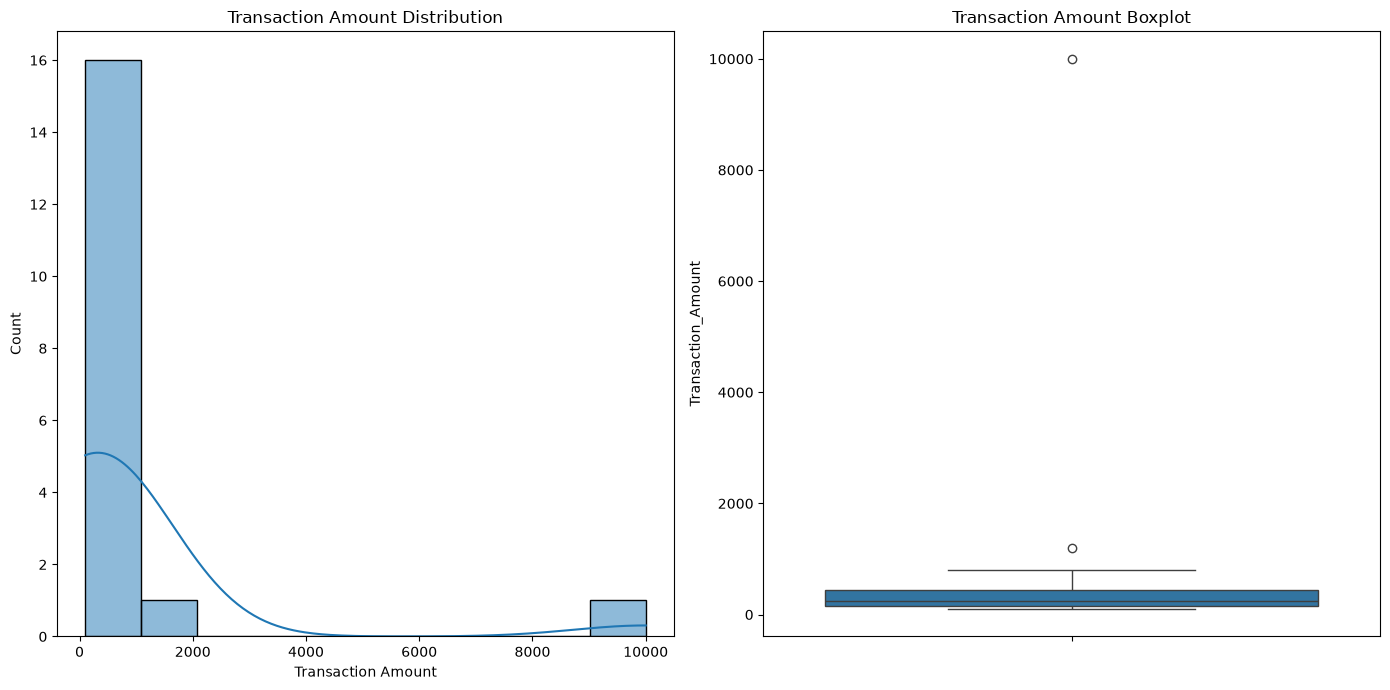

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

# Distribution plot
plt.subplot(1, 2, 1)
sns.histplot(
    df["Transaction_Amount"],
    kde=True,
    bins=10
)
plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")

# Boxplot
plt.subplot(1, 2, 2)
sns.boxplot(y=df["Transaction_Amount"])
plt.title("Transaction Amount Boxplot")

plt.tight_layout()
plt.show()


Question 4: Outlier Detection in Student Performance

Study Hours Q1: 2.75
Study Hours Q3: 5.25
Study Hours IQR: 2.5
Study Hours Bounds: -1.0 9.0

Exam Score Q1: 47.25
Exam Score Q3: 69.0
Exam Score IQR: 21.75
Exam Score Bounds: 14.625 101.625

Outlier Detection Table:
    Student_ID  Study_Hours  Exam_Score  Study_IQR  Score_IQR  Study_Z  \
0            1            1          35      False      False    False   
1            2            2          40      False      False    False   
2            3            2          45      False      False    False   
3            4            3          48      False      False    False   
4            5            3          52      False      False    False   
5            6            4          55      False      False    False   
6            7            4          60      False      False    False   
7            8            5          65      False      False    False   
8            9            5          68      False      False    False   
9           10            6          72     

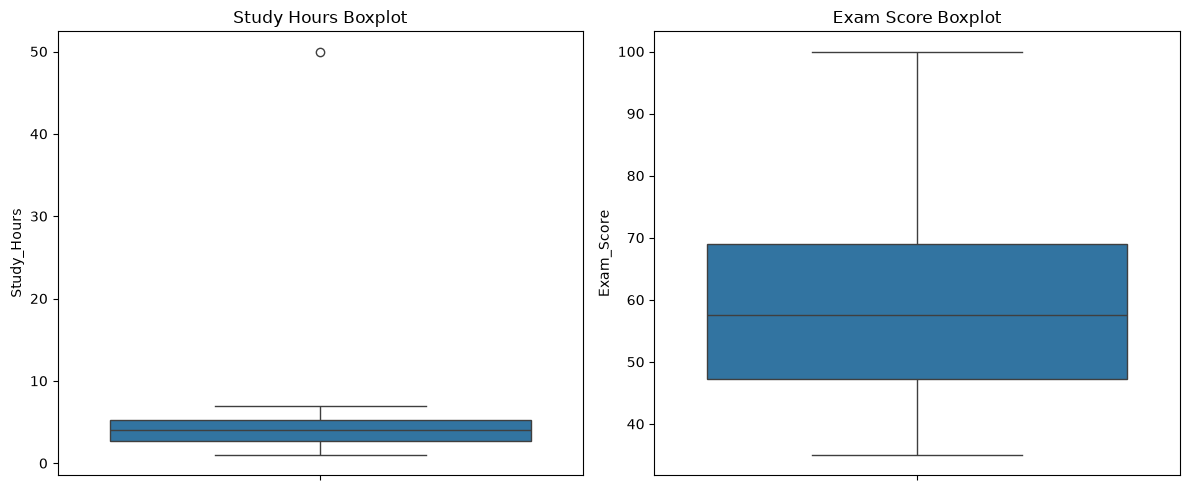

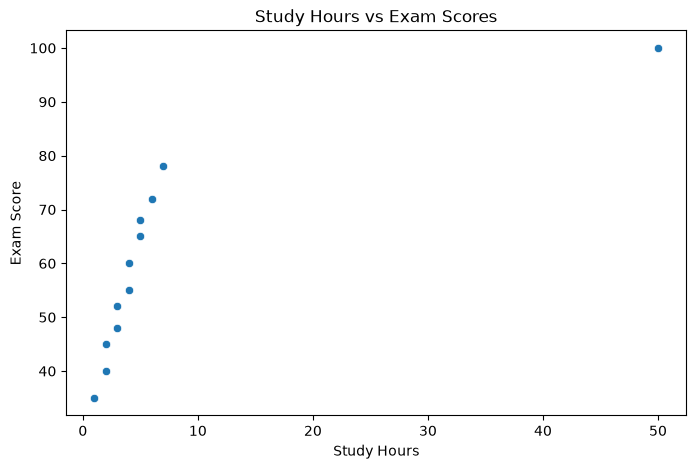

In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

df = pd.DataFrame({
    "Student_ID": range(1, 13),
    "Study_Hours": [1, 2, 2, 3, 3, 4,
                    4, 5, 5, 6, 7, 50],
    "Exam_Score": [35, 40, 45, 48, 52, 55,
                   60, 65, 68, 72, 78, 100]
})

# IQR for Study Hours
Q1_study = df["Study_Hours"].quantile(0.25)
Q3_study = df["Study_Hours"].quantile(0.75)
IQR_study = Q3_study - Q1_study

lower_study = Q1_study - 1.5 * IQR_study
upper_study = Q3_study + 1.5 * IQR_study

# IQR for Exam Score
Q1_score = df["Exam_Score"].quantile(0.25)
Q3_score = df["Exam_Score"].quantile(0.75)
IQR_score = Q3_score - Q1_score

lower_score = Q1_score - 1.5 * IQR_score
upper_score = Q3_score + 1.5 * IQR_score

# IQR outlier flags
df["Study_IQR"] = (
    (df["Study_Hours"] < lower_study) |
    (df["Study_Hours"] > upper_study)
)

df["Score_IQR"] = (
    (df["Exam_Score"] < lower_score) |
    (df["Exam_Score"] > upper_score)
)

# Z-score outlier flags
df["Study_Z"] = abs(zscore(df["Study_Hours"])) > 3
df["Score_Z"] = abs(zscore(df["Exam_Score"])) > 3

print("Study Hours Q1:", Q1_study)
print("Study Hours Q3:", Q3_study)
print("Study Hours IQR:", IQR_study)
print("Study Hours Bounds:", lower_study, upper_study)

print("\nExam Score Q1:", Q1_score)
print("Exam Score Q3:", Q3_score)
print("Exam Score IQR:", IQR_score)
print("Exam Score Bounds:", lower_score, upper_score)

print("\nOutlier Detection Table:")
print(df)

# Boxplots
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df["Study_Hours"])
plt.title("Study Hours Boxplot")

plt.subplot(1, 2, 2)
sns.boxplot(y=df["Exam_Score"])
plt.title("Exam Score Boxplot")

plt.tight_layout()
plt.show()

# Scatterplot
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Study_Hours",
    y="Exam_Score"
)

plt.title("Study Hours vs Exam Scores")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.show()
